In [ ]:
#Output is Reconstruction Loss(high for )

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import accuracy_score, precision_score, recall_score,confusion_matrix
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, losses
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Model
from sklearn.preprocessing import MinMaxScaler

dataframe=pd.read_csv('creditcard.csv')

In [18]:
dataframe

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [19]:
dataframe.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [20]:
dataframe.isnull()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
284803,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
284804,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
284805,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [21]:
(dataframe==1).sum()

Time          2
V1            0
V2            0
V3            0
V4            0
V5            0
V6            0
V7            0
V8            0
V9            0
V10           0
V11           0
V12           0
V13           0
V14           0
V15           0
V16           0
V17           0
V18           0
V19           0
V20           0
V21           0
V22           0
V23           0
V24           0
V25           0
V26           0
V27           0
V28           0
Amount    13688
Class       492
dtype: int64

In [22]:
dataframe=dataframe.drop(columns="Time")

In [23]:
from sklearn.model_selection import train_test_split
labels =dataframe['Class']
data = dataframe.drop(columns=['Class'])
print(labels.shape," ",data.shape)

(284807,)   (284807, 29)


In [24]:
train_data, test_data, train_labels, test_labels = train_test_split(
    data, labels, test_size=0.2, random_state=21
)

In [25]:
scaler = MinMaxScaler()

In [26]:
train_data_scaled = scaler.fit_transform(train_data)
test_data_scaled = scaler.transform(test_data)

In [27]:
print("Training data shape:", train_data_scaled.shape)
print("Testing data shape :", test_data_scaled.shape)

Training data shape: (227845, 29)
Testing data shape : (56962, 29)


In [28]:
train_data_scaled = train_data_scaled.astype("float32")
test_data_scaled =test_data_scaled.astype("float32")

In [29]:
class AnomalyDetector(Model):
  def __init__(self):
    super(AnomalyDetector, self).__init__()
    self.encoder = tf.keras.Sequential([
      layers.Dense(32, activation="relu"),
      layers.Dense(16, activation="relu"),
      layers.Dense(8, activation="relu")])

    self.decoder = tf.keras.Sequential([
      layers.Dense(16, activation="relu"),
      layers.Dense(32, activation="relu"),
      layers.Dense(29, activation="sigmoid")])

  def call(self, x):
    encoded = self.encoder(x)
    decoded = self.decoder(encoded)
    return decoded

autoencoder = AnomalyDetector()


In [30]:
autoencoder.compile(optimizer='adam', loss='mse')


In [31]:
history = autoencoder.fit(train_data_scaled, train_data_scaled,
          epochs=50,
          batch_size=512,
          validation_data=(test_data_scaled, test_data_scaled),
          shuffle=True)


Epoch 1/50
446/446 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 0.0057 - val_loss: 0.0016
Epoch 2/50
446/446 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0015 - val_loss: 0.0013
Epoch 3/50
446/446 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0013 - val_loss: 0.0013
Epoch 4/50
446/446 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 5/50
446/446 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0012 - val_loss: 0.0011
Epoch 6/50
446/446 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0011 - val_loss: 0.0011
Epoch 7/50
446/446 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0011 - val_loss: 0.0011
Epoch 8/50
446/446 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0011 - val_loss: 0.0011
Epoch 9/50
446/446 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0010 - val_loss: 0.0010
Epoch 10/50
446/446 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0010 - val_loss: 0.0012
Epoch 11/50
446/446 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 9.9885e-04 - val_loss: 9.7069e-04
Epoch 12/50
446/446 ━━━━━━━━━━━━━━━━━━━━ 2s 

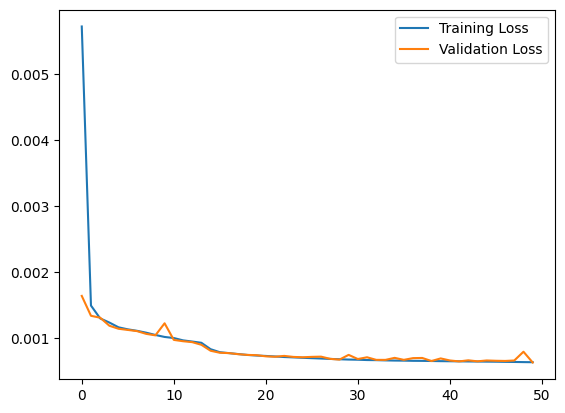

In [32]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()

In [33]:
X_train_reconstructed = autoencoder.predict(
    train_data_scaled,
    batch_size=512,
    verbose=0
)

In [34]:
print(
    "Original shape:",
    train_data_scaled.shape
)
print(
    "Reconstructed shape:",
    X_train_reconstructed.shape
)

Original shape: (227845, 29)
Reconstructed shape: (227845, 29)


In [35]:
normal_error = np.mean(
    np.square(
        train_data_scaled- 
        X_train_reconstructed
    ),
    axis=1
)
print("Normal reconstruction error:")
print(normal_error[:10])


Normal reconstruction error:
[0.00063803 0.00040806 0.0004457  0.00016282 0.00030135 0.00074076
 0.00062873 0.00026255 0.00050912 0.00024311]


In [36]:
threshold = np.percentile(
    normal_error,
    95
)

In [37]:
print(
    "Anomaly Threshold:",
    threshold
)

Anomaly Threshold: 0.0015312986


In [38]:
X_test_reconstructed = autoencoder.predict(
    test_data_scaled,
    batch_size=512,
    verbose=0
)

In [39]:
print(
    "Test reconstructed shape:",
    X_test_reconstructed.shape
)

Test reconstructed shape: (56962, 29)


In [40]:
test_error = np.mean(
    np.square(
        test_data_scaled -
        X_test_reconstructed
    ),
    axis=1
)

In [41]:
print("First 10 test errors:")
print(test_error[:10])

First 10 test errors:
[0.00251285 0.0009865  0.00204466 0.000467   0.00094273 0.00043443
 0.00058238 0.00028254 0.00023466 0.00055816]


In [42]:
y_pred = (
    test_error > threshold
).astype(int)
print("Predicted classes:")
print(y_pred[:20])


Predicted classes:
[1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [43]:
results = pd.DataFrame({
    "Actual_Class": test_labels.values,
    "Reconstruction_Error": test_error,
    "Predicted_Class": y_pred
})

In [44]:
results.head(20)

,Actual_Class,Reconstruction_Error,Predicted_Class
0,0,0.002513,1
1,0,0.000987,0
2,0,0.002045,1
3,0,0.000467,0
4,0,0.000943,0
5,0,0.000434,0
6,0,0.000582,0
7,0,0.000283,0
8,0,0.000235,0
9,0,0.000558,0


In [45]:
accuracy = accuracy_score(
    test_labels,
    y_pred
)
print("Accuracy:", accuracy)

Accuracy: 0.9506162002738668


In [46]:
cm = confusion_matrix(
    test_labels,
    y_pred
)
print(cm)

[[54066  2787]
 [   26    83]]


In [48]:
index = int(input("Enter transaction index: "))

transaction = data.loc[[index]]
transaction_scaled = scaler.transform(transaction).astype("float32")
reconstructed = autoencoder.predict(
    transaction_scaled,
    verbose=0
)

reconstruction_loss = np.mean(
    np.square(
        transaction_scaled - reconstructed
    ),
    axis=1
)[0]

if reconstruction_loss > threshold:
    result = "FRAUD"
else:
    result = "NORMAL"

print("\nReconstruction Loss:", reconstruction_loss)
print("Threshold:", threshold)
print("Prediction:", result)

Enter transaction index:  4920



Reconstruction Loss: 0.0021731523
Threshold: 0.0015312986
Prediction: FRAUD
